<a href="https://colab.research.google.com/github/AHMADMALIK1376/Artificial-Intelligence/blob/main/Lab2_Problem_Formulation_8_Puzzle.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lab # 2: Problem Formulation and the 8-Puzzle Problem

**Subject:** Artificial Intelligence (CMC381-L)
**Student Name:** [Your Name]
**Roll Number:** [Your Roll No.]
**Date:** [Insert Date]
**Instructor:** [Instructor Name]

---

## Objective
To learn how to formulate a problem as a search problem, implement the 8-puzzle problem, and measure solving performance by tracking node expansion.

## Theory Summary

### Components of a Well-Defined Problem
1. **State space** — all reachable states
2. **Initial state** — where the agent starts
3. **Actions** — ACTIONS(s) returns legal moves in state s
4. **Transition model** — RESULT(s, a) returns the next state
5. **Goal test** — checks whether a state is the goal
6. **Path cost** — numeric cost of a path (optimal = lowest cost)

### The 8-Puzzle
- 3×3 board, tiles 1–8 and one blank (0)
- Total reachable states = 9! / 2 = **181,440**
- Goal state: `(1, 2, 3, 4, 5, 6, 7, 8, 0)`
- Each move costs 1

### Solvability
- Count inversions (pairs where a bigger tile appears before a smaller one, ignoring blank).
- **Solvable if inversions are even.**

In [30]:
# =========================================================
# LAB 2: 8-Puzzle Problem Formulation and BFS Solver
# =========================================================

from collections import deque
import time
import random

# -------- Goal State & Move Offsets --------
GOAL = (1, 2, 3,
        4, 5, 6,
        7, 8, 0)       # 0 = blank tile

MOVES = {'Up': -3, 'Down': 3, 'Left': -1, 'Right': 1}


# -------- Problem Formulation --------
def actions(state):
    """Return the legal moves of the blank tile."""
    i = state.index(0)
    row, col = divmod(i, 3)
    legal = []
    if row > 0: legal.append('Up')
    if row < 2: legal.append('Down')
    if col > 0: legal.append('Left')
    if col < 2: legal.append('Right')
    return legal


def result(state, action):
    """Transition model: swap blank with neighbour."""
    i = state.index(0)
    j = i + MOVES[action]
    s = list(state)
    s[i], s[j] = s[j], s[i]
    return tuple(s)


def goal_test(state):
    return state == GOAL


def is_solvable(state):
    """Check solvability by counting inversions."""
    tiles = [t for t in state if t != 0]
    inversions = sum(1 for a in range(len(tiles))
                     for b in range(a + 1, len(tiles))
                     if tiles[a] > tiles[b])
    return inversions % 2 == 0


# -------- BFS Solver --------
def solve_bfs(start):
    """Breadth-First Search. Returns (path, nodes_expanded, nodes_generated, time_ms)."""
    if not is_solvable(start):
        return None, 0, 0, 0.0

    t0 = time.perf_counter()

    frontier = deque([(start, [])])
    explored = {start}
    expanded = 0
    generated = 1

    while frontier:
        state, path = frontier.popleft()

        if goal_test(state):
            t1 = time.perf_counter()
            return path, expanded, generated, (t1 - t0) * 1000

        expanded += 1
        for a in actions(state):
            child = result(state, a)
            if child not in explored:
                explored.add(child)
                generated += 1
                frontier.append((child, path + [a]))

    t1 = time.perf_counter()
    return None, expanded, generated, (t1 - t0) * 1000


# -------- Pretty Printer --------
def show(state):
    """Print the board in a 3x3 layout."""
    for r in range(3):
        print(' '.join(str(x) if x else '_' for x in state[r*3:r*3+3]))


# -------- Sanity Check with Example Start --------
print("=" * 55)
print("SANITY CHECK — Example Start State")
print("=" * 55)

start = (1, 2, 3,
         4, 0, 6,
         7, 5, 8)

print("Start state:")
show(start)
print("Solvable:", is_solvable(start))

path, expanded, generated, ms = solve_bfs(start)
print("Solution :", path)
print("Moves    :", len(path))
print("Nodes expanded :", expanded)
print("Nodes generated:", generated)
print(f"Time taken     : {ms:.2f} ms")

SANITY CHECK — Example Start State
Start state:
1 2 3
4 _ 6
7 5 8
Solvable: True
Solution : ['Down', 'Right']
Moves    : 2
Nodes expanded : 8
Nodes generated: 16
Time taken     : 0.06 ms


In [31]:
# =========================================================
# TASK 1: Solve the start state (8, 1, 3, 4, 0, 2, 7, 6, 5)
# =========================================================

print("=" * 55)
print("TASK 1: Solve Given Start State")
print("=" * 55)

start = (8, 1, 3,
         4, 0, 2,
         7, 6, 5)

print("Start state:")
show(start)
print("Solvable:", is_solvable(start))
print("-" * 55)

path, expanded, generated, ms = solve_bfs(start)

if path is None:
    print("No solution found.")
else:
    print("Solution :", path)
    print("Moves    :", len(path))
    print("Nodes expanded :", expanded)
    print("Nodes generated:", generated)
    print(f"Time taken     : {ms:.2f} ms")

TASK 1: Solve Given Start State
Start state:
8 1 3
4 _ 2
7 6 5
Solvable: True
-------------------------------------------------------
Solution : ['Right', 'Down', 'Left', 'Left', 'Up', 'Up', 'Right', 'Down', 'Left', 'Down', 'Right', 'Up', 'Right', 'Down']
Moves    : 14
Nodes expanded : 5960
Nodes generated: 9021
Time taken     : 30.51 ms


In [32]:
# =========================================================
# TASK 2: print_solution(start, path)
# Prints the board after every move
# =========================================================

def print_solution(start, path):
    """Print the board after every move of the solution."""
    state = start
    print("Initial board:")
    show(state)
    print("-" * 15)

    for step, action in enumerate(path, 1):
        state = result(state, action)
        print(f"Step {step}: {action}")
        show(state)
        print("-" * 15)

    print(f"✅ Goal reached in {len(path)} moves.")


# Test on Task 1's state
start = (8, 1, 3,
         4, 0, 2,
         7, 6, 5)

path, _, _, _ = solve_bfs(start)

if path is not None:
    print_solution(start, path)

Initial board:
8 1 3
4 _ 2
7 6 5
---------------
Step 1: Right
8 1 3
4 2 _
7 6 5
---------------
Step 2: Down
8 1 3
4 2 5
7 6 _
---------------
Step 3: Left
8 1 3
4 2 5
7 _ 6
---------------
Step 4: Left
8 1 3
4 2 5
_ 7 6
---------------
Step 5: Up
8 1 3
_ 2 5
4 7 6
---------------
Step 6: Up
_ 1 3
8 2 5
4 7 6
---------------
Step 7: Right
1 _ 3
8 2 5
4 7 6
---------------
Step 8: Down
1 2 3
8 _ 5
4 7 6
---------------
Step 9: Left
1 2 3
_ 8 5
4 7 6
---------------
Step 10: Down
1 2 3
4 8 5
_ 7 6
---------------
Step 11: Right
1 2 3
4 8 5
7 _ 6
---------------
Step 12: Up
1 2 3
4 _ 5
7 8 6
---------------
Step 13: Right
1 2 3
4 5 _
7 8 6
---------------
Step 14: Down
1 2 3
4 5 6
7 8 _
---------------
✅ Goal reached in 14 moves.


TASK 3: Depth vs Nodes Expanded
 Depth |  Moves |  Expanded |  Generated |  Time (ms)
----------------------------------------------------------------------
     5 |      5 |        40 |         76 |       0.15
    10 |     10 |       445 |        735 |       1.21
    15 |     15 |      6638 |      10351 |      26.18
    20 |     20 |     53264 |      70425 |     276.41
    25 |     23 |    103525 |     127907 |     387.54


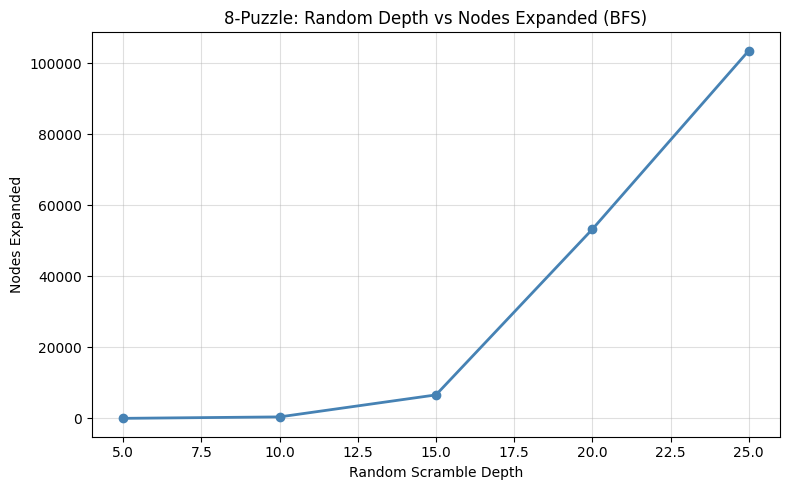

In [33]:
# =========================================================
# TASK 3: Generate 5 Random Solvable States
# Apply 5, 10, 15, 20, 25 random moves to GOAL
# Tabulate depth vs nodes expanded, then plot
# =========================================================

import matplotlib.pyplot as plt


def random_solvable_state(depth, seed=None):
    """Apply `depth` random moves to the goal state."""
    if seed is not None:
        random.seed(seed)
    state = GOAL
    previous = None
    for _ in range(depth):
        legal = actions(state)
        # Avoid undoing the previous move
        if previous:
            opposite = {'Up': 'Down', 'Down': 'Up',
                        'Left': 'Right', 'Right': 'Left'}[previous]
            legal = [a for a in legal if a != opposite] or legal
        a = random.choice(legal)
        state = result(state, a)
        previous = a
    return state


depths = [5, 10, 15, 20, 25]
results = []

print("=" * 70)
print("TASK 3: Depth vs Nodes Expanded")
print("=" * 70)
print(f"{'Depth':>6} | {'Moves':>6} | {'Expanded':>9} | {'Generated':>10} | {'Time (ms)':>10}")
print("-" * 70)

for d in depths:
    start = random_solvable_state(d, seed=d)
    path, expanded, generated, ms = solve_bfs(start)
    moves = len(path) if path else -1
    results.append((d, moves, expanded, generated, ms))
    print(f"{d:>6} | {moves:>6} | {expanded:>9} | {generated:>10} | {ms:>10.2f}")

# -------- Plot --------
depths_plot   = [r[0] for r in results]
expanded_plot = [r[2] for r in results]

plt.figure(figsize=(8, 5))
plt.plot(depths_plot, expanded_plot, marker='o', color='steelblue', linewidth=2)
plt.title("8-Puzzle: Random Depth vs Nodes Expanded (BFS)")
plt.xlabel("Random Scramble Depth")
plt.ylabel("Nodes Expanded")
plt.grid(True, alpha=0.4)
plt.tight_layout()
plt.show()

In [34]:
# =========================================================
# TASK 4: Test the Unsolvable State
# (1, 2, 3, 4, 5, 6, 8, 7, 0)
# =========================================================

# --- Safety: ensure the framework is loaded ---
try:
    is_solvable, solve_bfs, show
except NameError:
    raise RuntimeError(
        "❌ Please run Cell 3 (the 8-Puzzle framework) first, "
        "then re-run this cell."
    )

print("=" * 60)
print("TASK 4: Unsolvable State Handling")
print("=" * 60)

# The supposedly unsolvable start state
start = (1, 2, 3,
         4, 5, 6,
         8, 7, 0)

print("Start state:")
show(start)
print("-" * 60)

# --- Step 1: Check solvability ---
solvable = is_solvable(start)
print(f"Solvable? {solvable}")

# --- Step 2: Manually count inversions (proof) ---
tiles = [t for t in start if t != 0]
inversions = 0
inversion_pairs = []
for a in range(len(tiles)):
    for b in range(a + 1, len(tiles)):
        if tiles[a] > tiles[b]:
            inversions += 1
            inversion_pairs.append((tiles[a], tiles[b]))

print(f"Tile order (ignoring blank): {tiles}")
print(f"Inversion pairs: {inversion_pairs}")
print(f"Total inversions: {inversions}")
print(f"Parity: {'EVEN' if inversions % 2 == 0 else 'ODD'}")
print("-" * 60)

# --- Step 3: Behaviour of the solver ---
if not solvable:
    print("⚠️  This configuration is UNSOLVABLE.")
    print("Reason: The number of inversions is ODD.")
    print("→ The solver exits early WITHOUT searching.")
    print("→ This is the correct behaviour for problem-solving agents.")
else:
    path, expanded, generated, ms = solve_bfs(start)
    print("Solution :", path)
    print("Nodes expanded :", expanded)
    print("Nodes generated:", generated)
    print(f"Time taken     : {ms:.2f} ms")

print("=" * 60)

TASK 4: Unsolvable State Handling
Start state:
1 2 3
4 5 6
8 7 _
------------------------------------------------------------
Solvable? False
Tile order (ignoring blank): [1, 2, 3, 4, 5, 6, 8, 7]
Inversion pairs: [(8, 7)]
Total inversions: 1
Parity: ODD
------------------------------------------------------------
⚠️  This configuration is UNSOLVABLE.
Reason: The number of inversions is ODD.
→ The solver exits early WITHOUT searching.
→ This is the correct behaviour for problem-solving agents.


In [35]:
# =========================================================
# POST-LAB TASK: Missionaries and Cannibals Problem
# State: (M_left, C_left, boat_side)
#   boat_side: 1 = boat on left, 0 = boat on right
# Actions: move 1 or 2 people across, respecting rules
# =========================================================

from itertools import combinations

START = (3, 3, 1)   # 3M, 3C, boat on LEFT
GOAL_MC = (0, 0, 0) # all on RIGHT


def mc_actions(state):
    """Legal actions = boat carries 1 or 2 people from the current side."""
    M, C, boat = state
    people_side = M + C if boat == 1 else (3 - M) + (3 - C)
    if people_side < 1:
        return []

    # Possible boatloads: (m, c) combos with total 1 or 2
    loads = [(1, 0), (2, 0), (0, 1), (0, 2), (1, 1)]

    legal = []
    for m, c in loads:
        if boat == 1:
            if m <= M and c <= C:
                legal.append((m, c))
        else:
            if m <= (3 - M) and c <= (3 - C):
                legal.append((m, c))
    return legal


def mc_result(state, action):
    M, C, boat = state
    m, c = action
    if boat == 1:
        return (M - m, C - c, 0)
    else:
        return (M + m, C + c, 1)


def mc_goal(state):
    return state == GOAL_MC


def mc_valid(state):
    """Rules: missionaries must not be outnumbered on either side."""
    M, C, _ = state
    M_right, C_right = 3 - M, 3 - C

    # Left bank
    if M > 0 and M < C:
        return False
    # Right bank
    if M_right > 0 and M_right < C_right:
        return False
    return True


def solve_mc_bfs(start):
    frontier = deque([(start, [])])
    explored = {start}
    expanded = 0

    while frontier:
        state, path = frontier.popleft()
        if mc_goal(state):
            return path, expanded
        expanded += 1
        for a in mc_actions(state):
            child = mc_result(state, a)
            if child not in explored and mc_valid(child):
                explored.add(child)
                frontier.append((child, path + [a]))
    return None, expanded


# -------- Solve --------
print("=" * 60)
print("POST-LAB: Missionaries and Cannibals (BFS)")
print("=" * 60)

path, expanded = solve_mc_bfs(START)

if path is None:
    print("No solution found.")
else:
    print(f"Solution found in {len(path)} crossings:")
    state = START
    print(f"Start: {state}  (M_left, C_left, boat)")
    for i, (m, c) in enumerate(path, 1):
        state = mc_result(state, (m, c))
        direction = "→" if path[i-1] and i == 1 or True else ""
        print(f"Step {i:2d}: Move {m}M + {c}C  →  {state}")
    print(f"\nTotal crossings: {len(path)}")
    print(f"Nodes expanded : {expanded}")

POST-LAB: Missionaries and Cannibals (BFS)
Solution found in 11 crossings:
Start: (3, 3, 1)  (M_left, C_left, boat)
Step  1: Move 0M + 2C  →  (3, 1, 0)
Step  2: Move 0M + 1C  →  (3, 2, 1)
Step  3: Move 0M + 2C  →  (3, 0, 0)
Step  4: Move 0M + 1C  →  (3, 1, 1)
Step  5: Move 2M + 0C  →  (1, 1, 0)
Step  6: Move 1M + 1C  →  (2, 2, 1)
Step  7: Move 2M + 0C  →  (0, 2, 0)
Step  8: Move 0M + 1C  →  (0, 3, 1)
Step  9: Move 0M + 2C  →  (0, 1, 0)
Step 10: Move 1M + 0C  →  (1, 1, 1)
Step 11: Move 1M + 1C  →  (0, 0, 0)

Total crossings: 11
Nodes expanded : 14


## Viva Questions — Answers

**Q1. Difference between a state and a node?**
- **State:** A configuration of the world (e.g., a specific 8-puzzle board).
- **Node:** A data structure in the search tree that contains a state, plus the parent, action, and path cost.

**Q2. Why do we keep an explored set during search?**
To avoid revisiting states we've already processed. This prevents infinite loops in graphs with cycles, and reduces the number of nodes expanded.

**Q3. How many states are reachable in the 8-puzzle, and why only half of 9!?**
- Total arrangements = 9! = 362,880.
- Only states with an **even inversion count** are reachable from the goal.
- So reachable states = 9! / 2 = **181,440**.

**Q4. What is the branching factor of the 8-puzzle?**
- Maximum: **4** (blank in center).
- Minimum: **2** (blank in a corner).
- Average: approximately **2.67**.

---

## Summary

This lab introduced problem formulation using the 6 components (state space, initial state, actions, transition model, goal test, path cost). We implemented the **8-puzzle** with **BFS**, added a **solvability check** using inversion counting, and measured **nodes expanded** as a proxy for time complexity. Task 3 demonstrated exponential growth in nodes expanded as scramble depth increased — a direct illustration of BFS's time complexity, O(b^d).